# Approach 1 experiments and CodaBench export

This notebook compares BCE and Brier training, logistic regression, lexical text features, and SBERT features. It holds out one benchmark at a time and scores probabilities with equal weight for each subject-benchmark pair. The optional adaptation step uses only revealed labels.

By default this notebook displays the completed experiment. Set RUN_NEW_EXPERIMENT to True to train again, and choose a fresh RUN_NAME. The saved results are development scores, not a CodaBench score.

In [1]:
from pathlib import Path
import os
import sys

os.environ['KERAS_BACKEND'] = 'torch'
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'dl-project']
REPO = next((path for path in candidates if (path / 'dharaneesh/experiments.py').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open Jupyter from dl-project or dharaneesh.')
sys.path.insert(0, str(REPO))
DATA_DIR = Path(os.environ.get('AIMS_DATA_DIR', str(REPO.parent)))
print('Python:', sys.executable)
print('Repository:', REPO)
print('Data:', DATA_DIR)

Python: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\.venv-approach1\Scripts\python.exe
Repository: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project
Data: C:\Users\dhara\Downloads\aims\aims\data\measurement-db


## Settings

The default uses the four native binary benchmarks. MathArena and MMDocRAG contain fractional labels and are excluded, rather than silently thresholded. Each method uses identical held-out folds and duplicate-prompt grouping. The FNNs train with Keras's torch backend. The exported classifier uses NumPy and does not import TensorFlow or Keras.

In [2]:
RUN_NEW_EXPERIMENT = False
RUN_NAME = 'dharaneesh_comparison_01'
SEED = 42
EPOCHS = 20
METHODS = ['metadata_logistic', 'hash_text_logistic', 'sbert_logistic',
           'sbert_fnn_bce', 'sbert_fnn_brier']
ENCODER_DIR = os.environ.get('AIMS_ENCODER_DIR')

In [3]:
import pandas as pd
from IPython.display import display

if RUN_NEW_EXPERIMENT:
    from dharaneesh.experiments import load_examples
    examples, inventory = load_examples(DATA_DIR)
    display(pd.DataFrame(inventory)[['benchmark', 'rows', 'used', 'response_type']])
    display(examples.groupby('source').agg(attempts=('response','size'),
        unique_prompts=('prompt_group','nunique'), positive_rate=('response','mean')))
else:
    print('Recorded run: 136,282 responses, 8,794 distinct task texts, four binary benchmarks.')

Recorded run: 136,282 responses, 8,794 distinct task texts, four binary benchmarks.


## Train and compare

The outer benchmark is reserved for evaluation. An inner 80/20 prompt-grouped split selects the FNN checkpoint by validation Brier, even when training with BCE. Repeated responses remain together. The final chosen method is refit on all public binary rows for an epoch count selected beforehand. These are development scores, since the outer folds also guide method selection. They are not official hidden-test results.

In [4]:
if RUN_NEW_EXPERIMENT:
    from dharaneesh.experiments import run_experiments
    run_dir = run_experiments(DATA_DIR, RUN_NAME, METHODS, EPOCHS, SEED, ENCODER_DIR)
else:
    run_dir = REPO / 'dharaneesh/results'
    print('Displaying saved results:', run_dir)

Displaying saved results: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\results


,method,shrinkage,precision,mean_pair_alc,pair_count,B0,B1,B3,B7,B15,B31
0,metadata_logistic,0.5,1.0,0.198097,140,0.238338,0.220255,0.200646,0.187646,0.177150,0.171234
1,beta_mean,1.0,empirical,0.198661,140,0.250000,0.225051,0.199628,0.184788,0.174199,0.169273
2,sbert_fnn_brier,0.5,1.0,0.200122,140,0.246757,0.225428,0.202302,0.187711,0.176551,0.170477
3,sbert_fnn_bce,0.5,1.0,0.200361,140,0.247360,0.226061,0.202724,0.187727,0.176444,0.170338
5,hash_text_logistic,0.5,1.0,0.205496,140,0.244885,0.228750,0.209150,0.194967,0.183576,0.177186
16,sbert_logistic,0.5,1.0,0.220053,140,0.291511,0.258230,0.222692,0.200706,0.184724,0.176315
41,constant_0.5,1.0,none,0.250000,140,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000


,method,held_out,best_epoch,train_seconds,row_brier,pair_brier,accuracy,row_ece,pairs,rows
0,hash_text_logistic,multi_swebench,1,1.307741,0.255702,0.286316,0.589840,0.298577,82,57975
1,hash_text_logistic,real_webagents,1,3.537934,0.301331,0.306413,0.583277,0.237501,33,4449
2,hash_text_logistic,researchcodebench,1,2.309665,0.266261,0.264795,0.589328,0.175228,31,6784
3,hash_text_logistic,swe_rebench,1,1.504064,0.311819,0.311819,0.530668,0.212126,1,67074
4,metadata_logistic,multi_swebench,1,0.519312,0.227569,0.248009,0.617646,0.301279,82,57975
5,metadata_logistic,real_webagents,1,0.922869,0.259832,0.264853,0.578107,0.162132,33,4449
6,metadata_logistic,researchcodebench,1,0.646509,0.290209,0.285805,0.637235,0.240166,31,6784
7,metadata_logistic,swe_rebench,1,0.310980,0.272729,0.272729,0.520515,0.143875,1,67074
8,sbert_logistic,multi_swebench,1,0.948015,0.478132,0.475133,0.352169,0.543606,82,57975
9,sbert_logistic,real_webagents,1,1.916111,0.286188,0.289162,0.602607,0.206461,33,4449


{
  "run": "dharaneesh_20261011_v2",
  "selected": {
    "recipe_version": 1,
    "feature_mode": "metadata",
    "method": {
      "name": "metadata_logistic",
      "features": "metadata",
      "estimator": "logistic",
      "loss": "bce",
      "hidden": [
        64,
        16
      ],
      "dropout": 0.35,
      "l2": 0.0001
    },
    "shrinkage": 0.5,
    "adaptation_precision": 1.0,
    "encoder_max_seq_length": 256,
    "training_loss": "bce",
    "selection_metric": "held-out benchmark equal-pair simulated Brier ALC",
    "selection_is_development": true,
    "refit_epochs": 1
  },
  "selected_development_alc": 0.19809654195558213,
  "eligible_pair_count": 140,
  "final_checkpoint_validation": {
    "row_brier": 0.18935745207786334,
    "pair_brier": 0.17124340997233434,
    "accuracy": 0.6587834080883715,
    "row_ece": 0.020392825859616187,
    "pairs": 147,
    "rows": 26977
  },
  "checkpoint_training_seconds": 0.7474834001623094,
  "all_public_refit_seconds": 0.883798

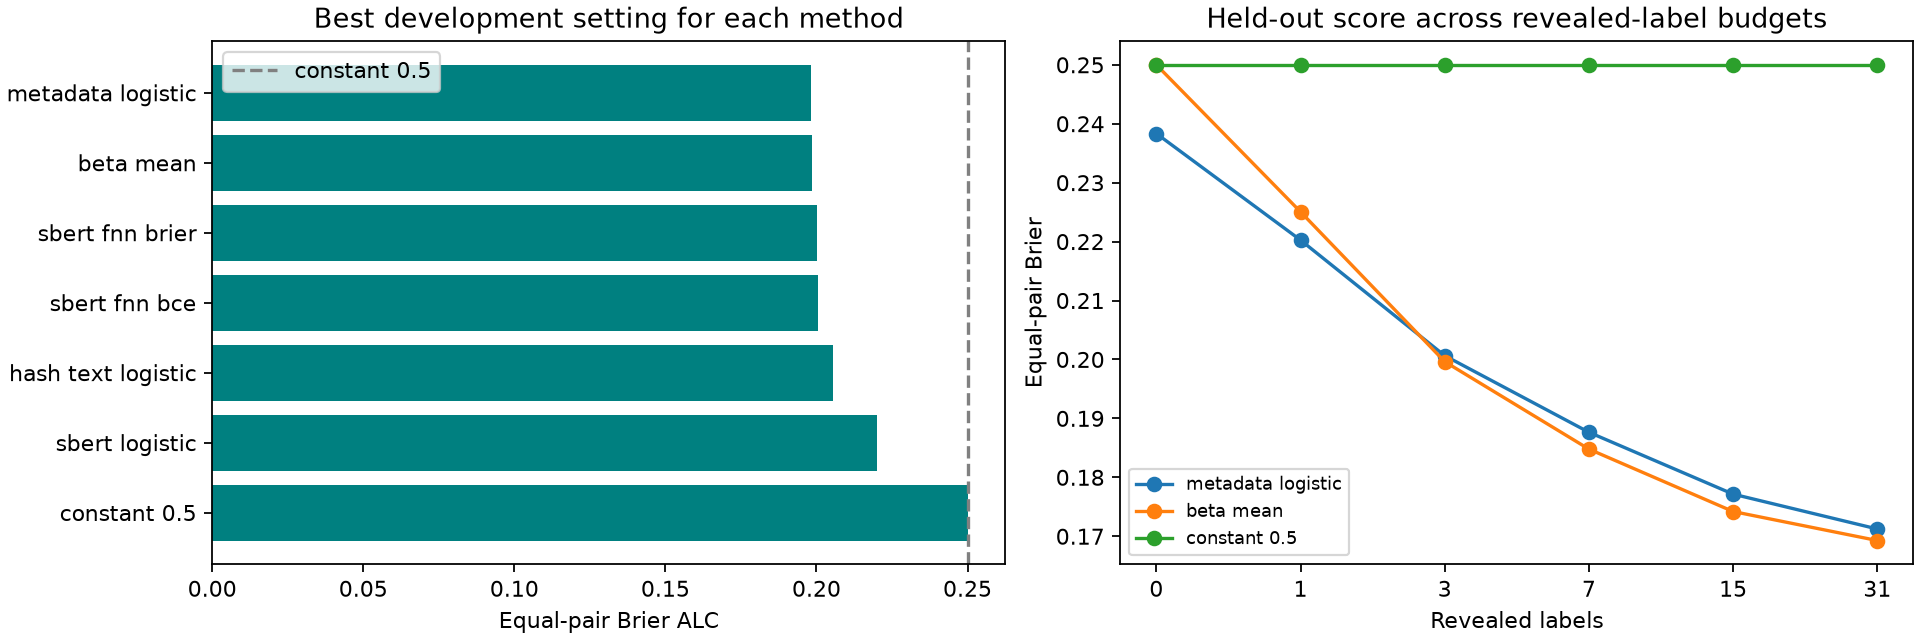

In [5]:
import json
from IPython.display import Image, display

comparison = pd.read_csv(run_dir / 'comparison.csv')
display(comparison.sort_values('mean_pair_alc').drop_duplicates('method'))
display(pd.read_csv(run_dir / 'held_out_scores.csv'))
summary = json.loads((run_dir / 'summary.json').read_text())
print(json.dumps(summary, indent=2))
display(Image(filename=str(run_dir / 'comparison.png')))

## Read the results

Lower Brier and lower Brier ALC are better. The constant 0.5 predictor has score 0.25. Compare both with the empirical-mean adaptation baseline. `shrinkage` moves predictions toward 0.5 when held-out evidence favors conservative probabilities. `precision` controls how strongly revealed labels can shift the base model; `none` is the no-adaptation Approach 1. L2 penalties are included only in the training objective, never in reported Brier scores.

Use the same held-out folds when comparing team implementations. A lower local score cannot guarantee a lower CodaBench score, whose formative sample changes between submissions.

## Submission file

The saved-results mode rebuilds `submission.zip` beside this notebook. It contains the selected metadata logistic model and revealed-label adaptation, not an FNN. A new training run instead exports its selected candidate and a separate no-adaptation comparison under the external dataset's approach1_outputs folder. Models and supporting files are at the ZIP root. The code runs offline and does not upload anything. Upload the ZIP yourself. Local tests do not prove hosted compatibility.

In [6]:
if RUN_NEW_EXPERIMENT:
    print('Candidate:', summary['zip'])
    print('Approach 1 only:', summary['approach1_zip'])
    print('SHA-256:', summary['zip_sha256'])
else:
    from dharaneesh.experiments import package_saved_submission
    candidate_zip = package_saved_submission()

Submission ZIP: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission.zip
SHA-256: c1d5aea56d6e59bb0133a31c2a20538ff579b95324d61f949ab3b3182c7b2363
